# Acknowledgements 
This notebook lab has been taken from the TBMI26 course (Neural networks and learning systems).

Examiner: Magnus Borga

Initial code authors (MATLAB version): UNKNOWN

Conversion to Python and overall refinement: Martin Hultman & David Abramian

### **Quick introduction to jupyter notebooks**
* Each cell in this notebook contains either code or text.
* You can run a cell by pressing Ctrl-Enter, or run and advance to the next cell with Shift-Enter.
* Code cells will print their output, including images, below the cell. Running it again deletes the previous output, so be careful if you want to save some results.
* You don't have to rerun all cells to test changes, just rerun the cell you have made changes to. Some exceptions might apply, for example if you overwrite variables from previous cells, but in general this will work.
* If all else fails, use the "Kernel" menu and select "Restart Kernel and Clear All Output". You can also use this menu to run all cells.
* A useful debug tool is the console. You can right-click anywhere in the notebook and select "New console for notebook". This opens a python console which shares the environment with the notebook, which let's you easily print variables or test commands.

### **Setup**

In [1]:
# Automatically reload modules when changed
%reload_ext autoreload
%autoreload 2
# Plot figures "inline" with other output
%matplotlib inline

# Import modules, classes, functions
from matplotlib import pyplot as plt
import numpy as np

from utils import loadDataset, splitData, plotProgress, plotProgressNetworkMulti, \
    plotResultsDots, plotIsolines, plotConfusionMatrixOCR, plotResultsDotsGradient
from evalFunctions import calcAccuracy, calcConfusionMatrix

# Configure nice figures
plt.rcParams['figure.facecolor']='white'
plt.rcParams['figure.figsize']=(8, 5)

### ***! IMPORTANT NOTE !***

Your implementation should only use the `numpy` (`np`) module. The `numpy` module provides all the functionality you need for this assignment and makes it easier debuging your code. No other modules, e.g. `scikit-learn` or `scipy` among others, are allowed. You can find everything you need about `numpy` in the official [documentation](https://numpy.org/doc/stable/).

### **1. Multi-layer neural network**

The implementation of the multi-layer network is a bit beyond the scope of this course, so we will provide it for you. Your task is instead to optimize the training and interpret tthe results.

Similar to the single-layer network, the multi-layer keep track of weight matrices `W1` and `W2`, and bias vectors `B1` and `B2`. The structure of the code is still the same, with a `forward`, `backward`, and `update` function.

#### **1.1 Implementing the forward pass**

This implementation will look similar to the single-layer code, but note that it also returns the intemediate variable `U`, which is the output of the hidden layer after passing throught the activation function. This will be used in the backward pass.

In [2]:
def forward(X, W1, B1, W2, B2, useTanhOutput=False):
    """Forward pass of two layer network

    Args:
        X (array): Input samples.
        W1 (array): First layer neural network weights.
        B1 (array): First layer neural network biases.
        W2 (array): Second layer neural network weights.
        B2 (array): Second layer neural network biases.

    Returns:
        Y (array): Output for each sample and class.
        L (array): Resulting label of each sample.
        U (array): Output of hidden layer.
    """

    # --------------------------------------------
    # === Your code here ========================= 
    # --------------------------------------------
    
    # Hidden layer: linear combination followed by the tanh nonlinearity.
    # It is this nonlinearity that makes the two-layer network more than
    # just a (slower) single-layer network.
    S = X @ W1 + B1        # (N, nHidden)
    U = np.tanh(S)         # (N, nHidden)
    
    # Output layer
    Y = U @ W2 + B2        # (N, nClasses)
    
    if useTanhOutput:
        Y = np.tanh(Y)
    
    # ============================================
    
    # Calculate labels
    L = Y.argmax(axis=1)

    return Y, L, U

#### **1.2 Implementing the backward pass**

This backward pass implementation uses the so called delta notation. This is very useful when implementing the general case of an N-layer network, since it can easily be implemnted in an iterative manner in a loop going over each layer. We will not do that in this assignment, but it is good to know that this is essentially how the popular frameworks for deep learning functions.

In [3]:
def backward(W1, B1, W2, B2, X, U, Y, D, useTanhOutput=False):
    """Compute the gradients for network weights and biases

    Args:
        W1 (array): Current values of the layer 1 network weights.
        B1 (array): Current values of the layer 1 network biases.
        W2 (array): Current values of the layer 2 network weights.
        B2 (array): Current values of the layer 2 network biases.
        X (array): Training samples.
        U (array): Intermediate outputs of the hidden layer.
        Y (array): Predicted outputs.
        D (array): Target outputs.
        
        useTanhOutput (bool): (optional)
            True  - Network uses tanh activation on output layer
            False - Network uses linear (no) activation on output layer
        
    Returns:
        GradW1 (array): Gradients with respect to W1
        GradB1 (array): Gradients with respect to B1
        GradW2 (array): Gradients with respect to W2
        GradB2 (array): Gradients with respect to B2
    """
    
    N  = Y.shape[0]
    NC = Y.shape[1]
    
    # --------------------------------------------
    # === Your code here =========================
    # --------------------------------------------
    
    # Delta of the output layer. The loss is mean((Y - D)**2), averaged over
    # both samples and classes, hence the factor 2/(N*NC).
    Delta2 = 2 / (N * NC) * (Y - D)              # (N, nClasses)
    
    # Chain rule through the optional output tanh: d/dz tanh(z) = 1 - Y**2
    if useTanhOutput:
        Delta2 = Delta2 * (1 - Y**2)
    
    # Gradient for the output layer
    GradW2 = U.T @ Delta2                        # (nHidden, nClasses)
    GradB2 = Delta2.sum(axis=0, keepdims=True)   # (1, nClasses)

    # Backpropagate the delta through W2 and through the hidden tanh
    Delta1 = (Delta2 @ W2.T) * (1 - U**2)        # (N, nHidden)
    
    # And the input layer
    GradW1 = X.T @ Delta1                        # (nInputs, nHidden)
    GradB1 = Delta1.sum(axis=0, keepdims=True)   # (1, nHidden)
    
    # ============================================
    
    return GradW1, GradB1, GradW2, GradB2

#### **1.3 Implementing the weight update**

For this update function we have implemented a more powerful algorithm called momentum gradient descent. This is part of an optional task at the end of the notebook, and you do not have to use it unless you want to.

In [4]:
def update(W1, B1, W2, B2, GradW1, GradB1, GradW2, GradB2, params):
    """Update weights and biases using computed gradients.

    Args:
        W1 (array): Current values of the layer 1 network weights.
        B1 (array): Current values of the layer 1 network biases.
        W2 (array): Current values of the layer 2 network weights.
        B2 (array): Current values of the layer 2 network biases.
        
        GradW1 (array): Gradients with respect to W1.
        GradB1 (array): Gradients with respect to B1.
        GradW2 (array): Gradients with respect to W2.
        GradB2 (array): Gradients with respect to B2.
        
        params (dict):
            - learningRate: Scale factor for update step.
            - momentum: Scale factor for momentum update (optional).
        
    Returns:
        W1 (array): Updated layer 1 weights.
        B1 (array): Updated layer 1 biases.
        W2 (array): Updated layer 2 weights.
        B2 (array): Updated layer 2 biases.
    """
    
    LR = params["learningRate"]
    
    # Uncomment this is you are working on the optional task on momentum.
    # M = params["momentum"]
    # PrevGradW1 = params["PrevGradW1"]
    # PrevGradB1 = params["PrevGradB1"]
    # PrevGradW2 = params["PrevGradW2"]
    # PrevGradB2 = params["PrevGradB2"]
    
    # --------------------------------------------
    # === Your code here =========================
    # --------------------------------------------
    
    # Update weights
    W1 = W1 - LR * GradW1
    B1 = B1 - LR * GradB1
    W2 = W2 - LR * GradW2
    B2 = B2 - LR * GradB2
        
    # --- Optional: momentum gradient descent ---
    # Uncomment the block below (and the params lines above) to blend each
    # gradient with the previous one, which damps oscillations across narrow
    # valleys and speeds up progress along consistent directions.
    #
    # GradW1 = GradW1 + M * PrevGradW1
    # GradB1 = GradB1 + M * PrevGradB1
    # GradW2 = GradW2 + M * PrevGradW2
    # GradB2 = GradB2 + M * PrevGradB2
    #
    # W1 = W1 - LR * GradW1
    # B1 = B1 - LR * GradB1
    # W2 = W2 - LR * GradW2
    # B2 = B2 - LR * GradB2
    #
    # params["PrevGradW1"] = GradW1
    # params["PrevGradB1"] = GradB1
    # params["PrevGradW2"] = GradW2
    # params["PrevGradB2"] = GradB2
        
    # ============================================
    
    return W1, B1, W2, B2
    

#### **1.4 The training function**

In [22]:
def trainMultiLayer(XTrain, DTrain, XTest, DTest, W1_0, B1_0, W2_0, B2_0, params):
    """Trains a two-layer network

    Args:
        XTrain (array): Training samples.
        DTrain (array): Training network target values.
        XTest (array): Test samples.
        DTest (array): Test network target values.
        W1_0 (array): Initial values of the first layer network weights.
        B1_0 (array): Initial values of the first layer network biases.
        W2_0 (array): Initial values of the second layer network weights.
        B2_0 (array): Initial values of the second layer network biases.
        params (dict): Dictionary containing:
            epochs (int): Number of training steps.
            learningRate (float): Size of a training step.

    Returns:
        W1 (array): First layer weights after training.
        B1 (array): Fisrt layer biases after training.
        W2 (array): Second layer weights after training.
        B2 (array): Second layer biases after training.
        metrics (dict): Losses and accuracies for training and test data.
    """

    # Initialize variables
    metrics = {keys:np.zeros(params["epochs"]+1) for keys in ["lossTrain", "lossTest", "accTrain", "accTest"]}

    if "useTanhOutput" not in params:
        params["useTanhOutput"] = False
        
    if "momentum" not in params:
        params["momentum"] = 0       
    
    nTrain = XTrain.shape[0]
    nTest  = XTest.shape[0]
    nClasses = DTrain.shape[1]
    
    # Set initial weights
    W1 = W1_0
    B1 = B1_0
    W2 = W2_0
    B2 = B2_0
    
    # For optional task on momentum
    params["PrevGradW1"] = np.zeros_like(W1)
    params["PrevGradB1"] = np.zeros_like(B1)
    params["PrevGradW2"] = np.zeros_like(W2)
    params["PrevGradB2"] = np.zeros_like(B2)

    # Get class labels
    LTrain = np.argmax(DTrain, axis=1)
    LTest  = np.argmax(DTest , axis=1)

    # Calculate initial metrics
    YTrain, LTrainPred, UTrain = forward(XTrain, W1, B1, W2, B2, params["useTanhOutput"])
    YTest , LTestPred , _      = forward(XTest , W1, B1, W2, B2, params["useTanhOutput"])
    
    # Including the initial metrics makes the progress plots worse, set nan to exclude
    metrics["lossTrain"][0] = np.nan # ((YTrain - DTrain)**2).mean()
    metrics["lossTest"][0]  = np.nan # ((YTest  - DTest )**2).mean()
    metrics["accTrain"][0]  = np.nan # (LTrainPred == LTrain).mean()
    metrics["accTest"][0]   = np.nan # (LTestPred  == LTest ).mean()

    # Create figure for plotting progress
    fig = plt.figure(figsize=(20,8), tight_layout=True)

    # Training loop
    for n in range(1, params["epochs"]+1):
        
        # --------------------------------------------
        # === This is the important part =============
        # === where your code is applied =============
        # --------------------------------------------
        
        # Compute gradients...
        GradW1, GradB1, GradW2, GradB2 = backward(W1, B1, W2, B2, XTrain, UTrain, YTrain, DTrain, params["useTanhOutput"])
        # ... and update weights
        W1, B1, W2, B2 = update(W1, B1, W2, B2, GradW1, GradB1, GradW2, GradB2, params)
        
        # ============================================
        
        # Evaluate errors
        YTrain, LTrainPred, UTrain = forward(XTrain, W1, B1, W2, B2, params["useTanhOutput"])
        YTest , LTestPred , _      = forward(XTest , W1, B1, W2, B2, params["useTanhOutput"])
        metrics["lossTrain"][n] = ((YTrain - DTrain)**2).mean()
        metrics["lossTest"][n]  = ((YTest  - DTest )**2).mean()
        metrics["accTrain"][n]  = (LTrainPred == LTrain).mean()
        metrics["accTest"][n]   = (LTestPred  == LTest ).mean()

        # Plot progress
        if (plotProgress and not n % 500) or n == params["epochs"]:
            if W1.shape[0] == 2 and W1.shape[1] <= 8:
                plotProgressNetworkMulti(fig, W1, B1, W2, B2, metrics, n=n)
            else:
                plotProgress(fig, metrics, n)

    #print("NaN in weights:", np.isnan(W1).any(), np.isnan(W2).any())

    return W1, B1, W2, B2, metrics

We also define the same function for normalizing the data, which is even more important now that we have more than one layer.

In [23]:
def normalize(X):
    # Compute mean and std
    m = X.mean(axis=0)
    s = X.std(axis=0)
    # Prevent division by 0 is feature has no variance
    s[s == 0] = 1
    # Return normalized data
    return (X - m) / s

#### **<span style="color:red">Question</span>**

1. Explain why large, non-normalized input features might be a problem when using two layers, but not when using a single layer.

#### **<span style="color:green">Answer:</span>**

The difference is the tanh in the hidden layer.

With one layer the output is just X·W + B. If the inputs get 10 times bigger, the weights
can get 10 times smaller and the result is exactly the same. So large inputs only mean we
need a smaller learning rate, they do not change what the network can do.

With two layers the hidden layer computes tanh(X·W1 + B1). tanh only reacts to values
roughly between -2 and 2. Outside that it is flat at -1 or +1. If the inputs are large,
the hidden units are flat from the start, and the gradient going into the first layer is
multiplied by (1 - U²), which is then almost zero. So the first layer stops learning and
the network is stuck. Normalizing the data keeps the hidden units in the useful part of
tanh, which is why it matters much more here.

---
### **2 Optimizing each dataset**

Like before, we define a function that performs the boilerplate code for training the networks.

In [24]:
def  trainMultiLayerOnDataset(datasetNr, testSplit, W1_0, B1_0, W2_0, B2_0, params):
    """Train a two layer network on a specific dataset.

    Ags:
        datasetNr (int): ID of dataset to use
        testSplit (float): Fraction of data reserved for testing.
        W1_0 (array): Initial values of the first layer network weights.
        B1_0 (array): Initial values of the first layer network biases.
        W2_0 (array): Initial values of the second layer network weights.
        B2_0 (array): Initial values of the second layer network biases.
        params (dict): Dictionary containing:
            nIterations (int): Number of training steps.
            learningRate (float): Size of a training step.
    """
    
    # Load data and split into training and test sets
    X, D, L = loadDataset(datasetNr)
    XTrain, DTrain, LTrain, XTest, DTest, LTest = splitData(X, D, L, testSplit)
    
    if "normalize" in params and params["normalize"]:
        XTrainNorm = normalize(XTrain)
        XTestNorm  = normalize(XTest)
    else:
        XTrainNorm = XTrain
        XTestNorm  = XTest

    # Train network
    W1, B1, W2, B2, metrics = trainMultiLayer(XTrainNorm, DTrain, XTestNorm, DTest, W1_0, B1_0, W2_0, B2_0, params)

    # Predict classes on test set
    LPredTrain = forward(XTrainNorm, W1, B1, W2, B2, params["useTanhOutput"])[1]
    LPredTest  = forward(XTestNorm , W1, B1, W2, B2, params["useTanhOutput"])[1]

    # Compute metrics
    accTrain = calcAccuracy(LPredTrain, LTrain)
    accTest  = calcAccuracy(LPredTest , LTest)
    confMatrix = calcConfusionMatrix(LPredTest, LTest)

    # Display results
    print(f'Train accuracy: {accTrain:.4f}')
    print(f'Test accuracy: {accTest:.4f}')
    print("Test data confusion matrix:")
    print(confMatrix)

    if datasetNr < 4:
        # Switch between these two functions to see another way to visualize the network output.
        plotResultsDots(XTrainNorm, LTrain, LPredTrain, XTestNorm, LTest, LPredTest, lambda X: forward(X, W1, B1, W2, B2, params["useTanhOutput"])[1])
        #plotResultsDotsGradient(XTrainNorm, LTrain, LPredTrain, XTestNorm, LTest, LPredTest, lambda X: forward(X, W1, B1, W2, B2, params["useTanhOutput"])[0])
    else:
        plotConfusionMatrixOCR(XTest, LTest, LPredTest)

#### **2.1 Optimizing dataset 1**

Train accuracy: 0.9918
Test accuracy: 0.9833
Test data confusion matrix:
[[152   1]
 [  4 143]]


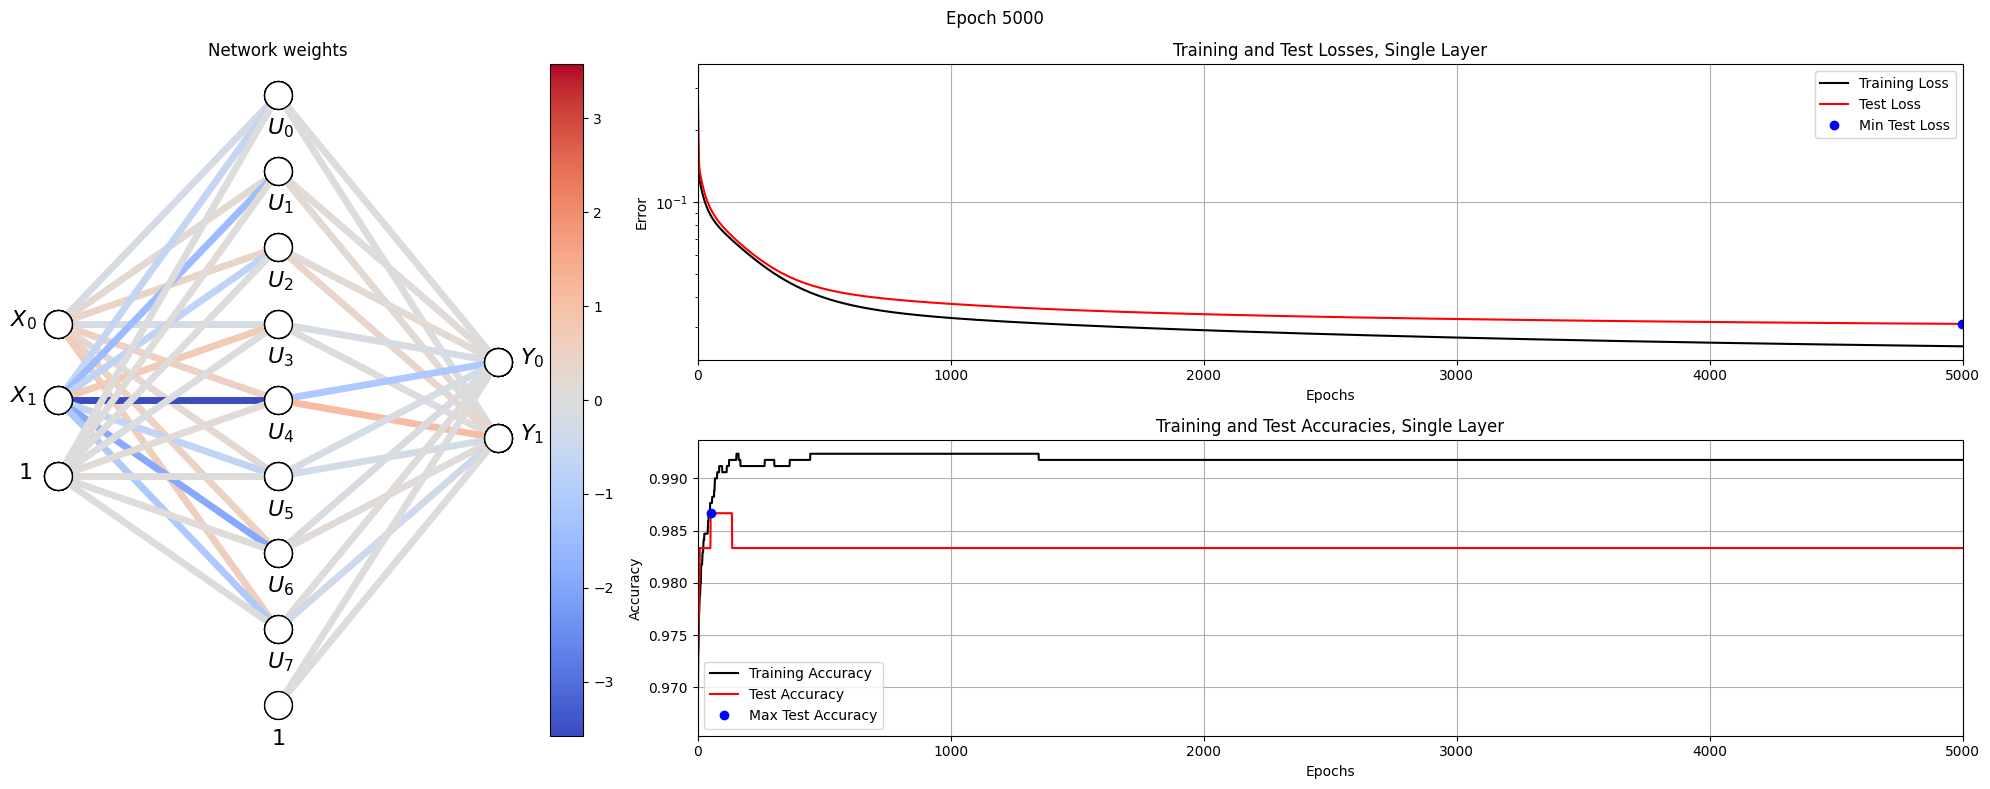

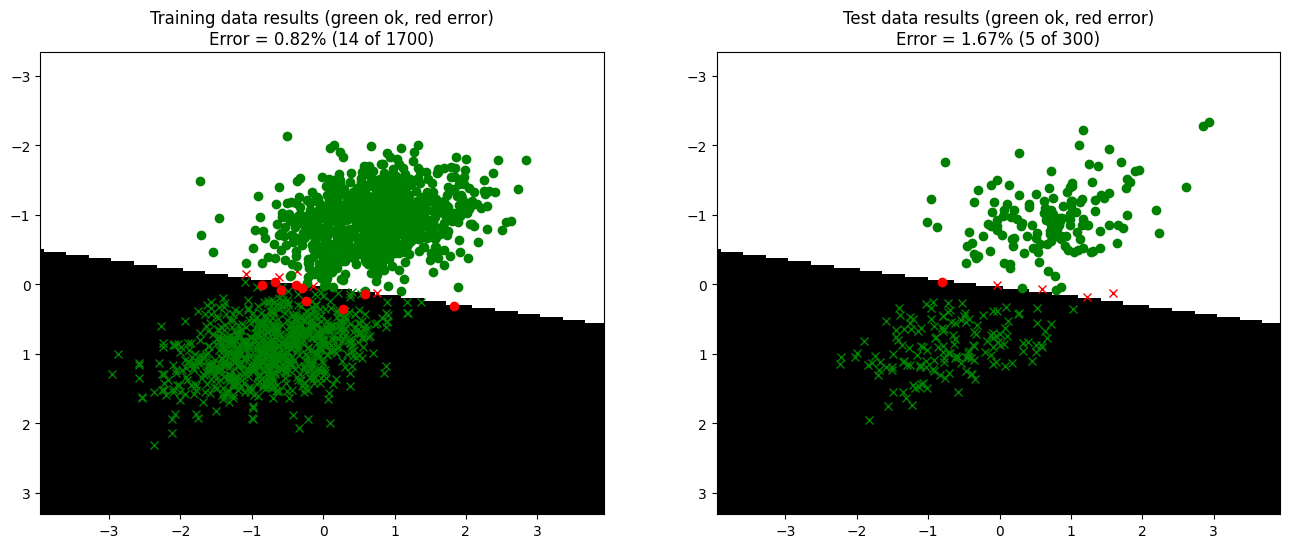

In [25]:
# --------------------------------------------
# === Your code here ========================= 
# --------------------------------------------
X, D, _ = loadDataset(1)

nInputs  = X.shape[1]
nClasses = D.shape[1]
nHidden  = 8

# Xavier-style initialization: scale each layer by 1 / sqrt(fan-in) so that the
# hidden units start in the non-saturated part of tanh. The weights must be
# random here (unlike the single-layer case) — identical hidden units would
# receive identical gradients forever and never differentiate.
rng = np.random.default_rng(seed=0)
W1_0 = rng.normal(loc=0.0, scale=1 / np.sqrt(nInputs), size=(nInputs, nHidden))
B1_0 = np.zeros((1, nHidden))
W2_0 = rng.normal(loc=0.0, scale=1 / np.sqrt(nHidden), size=(nHidden, nClasses))
B2_0 = np.zeros((1, nClasses))

params = {"epochs": 5000, "learningRate": 0.1, "normalize": True, "useTanhOutput": False}
# ============================================

trainMultiLayerOnDataset(1, 0.15, W1_0, B1_0, W2_0, B2_0, params)

#### **<span style="color:red">Question:</span>**

2. Optimize the training until you reach at least 98% test accuracy. Briefly motivate your choice of hyperparameters.

#### **<span style="color:green">Answer:</span>**

I used nHidden=8, epochs=5000, learningRate=0.1, normalize=True, no tanh output.
This gave 99.18% train and 98.33% test accuracy, above the 98% target.

Dataset 1 is almost linearly separable, so very little hidden capacity is needed and 8
hidden units are plenty. The weights have to be random here, unlike the single layer case,
because identical hidden units would get identical gradients and stay identical forever.

The learning rate was the part that mattered. With learningRate=1.0 the weights overflowed
to NaN during training, so every point was labelled class 0 and the result was 50% accuracy
with a confusion matrix of [[146 154],[0 0]]. I checked this directly with np.isnan on the
weights after training. Lowering the learning rate to 0.1 keeps the steps small enough to
stay stable, and 5000 epochs is enough for the loss to level out. Only 5 of 300 test points
are wrong, and they sit on the boundary where the two clusters overlap.

The data is re-split randomly on every run, so the exact numbers move by a few tenths of a
percent. Across several runs the test accuracy stayed between 98.33% and 99.33%.

#### **2.2 Optimizing dataset 2**

Train accuracy: 0.9994
Test accuracy: 0.9967
Test data confusion matrix:
[[142   0]
 [  1 157]]


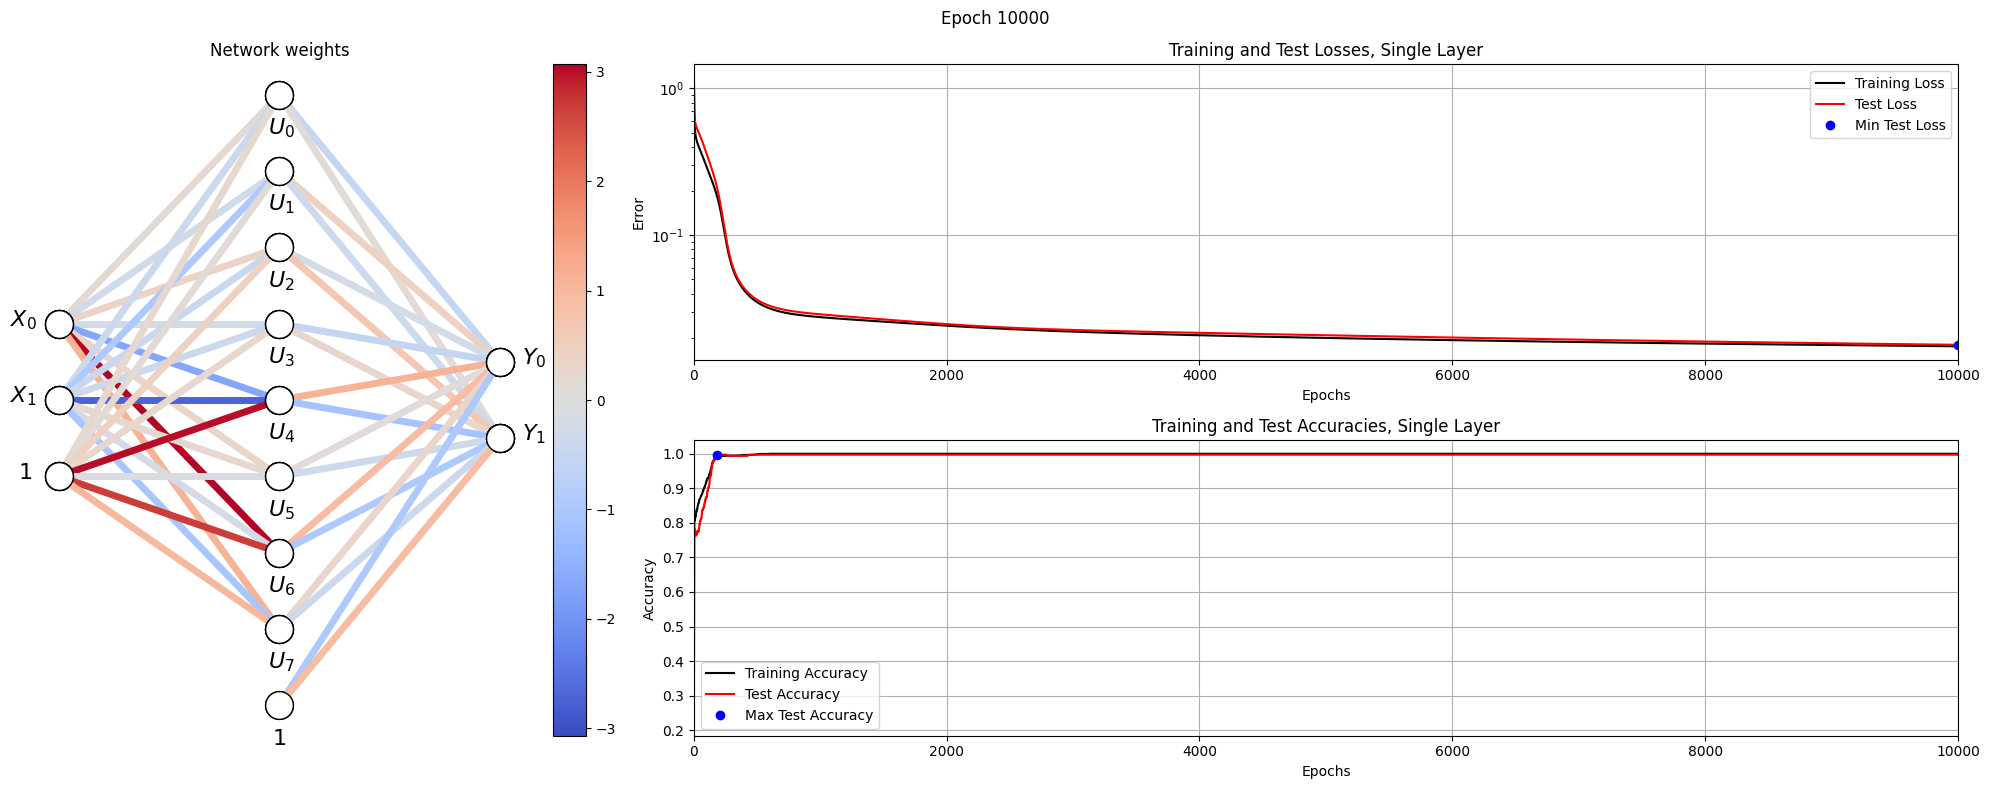

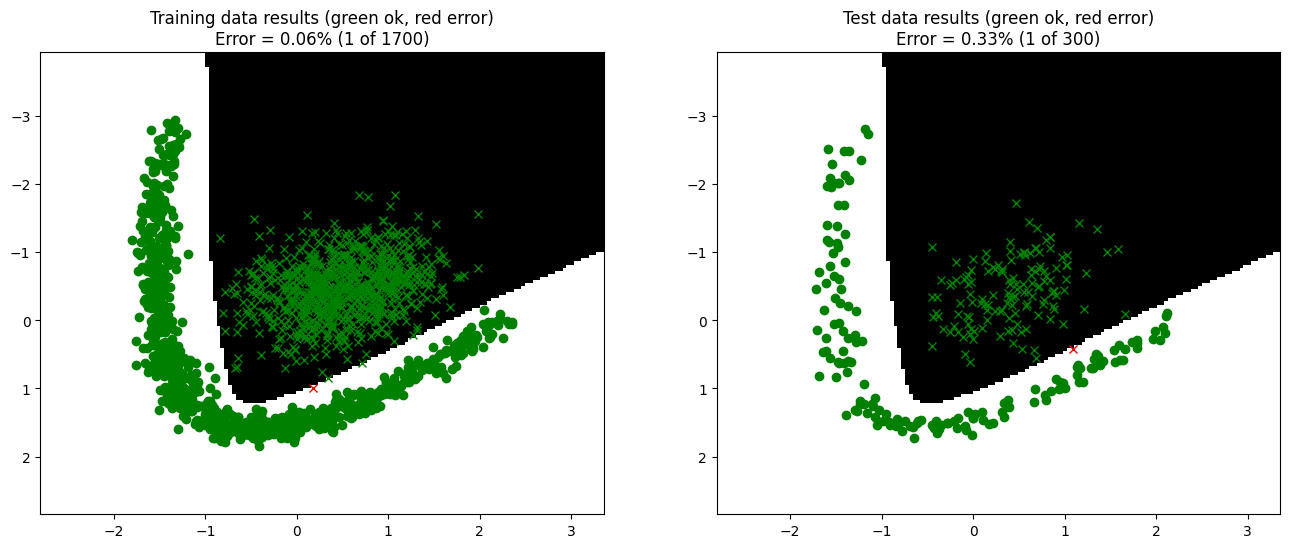

In [13]:
# --------------------------------------------
# === Your code here ========================= 
# --------------------------------------------
X, D, _ = loadDataset(2)

nInputs  = X.shape[1]
nClasses = D.shape[1]
nHidden  = 8

# Xavier-style initialization: scale each layer by 1 / sqrt(fan-in) so that the
# hidden units start in the non-saturated part of tanh. The weights must be
# random here (unlike the single-layer case) — identical hidden units would
# receive identical gradients forever and never differentiate.
rng = np.random.default_rng(seed=0)
W1_0 = rng.normal(loc=0.0, scale=1 / np.sqrt(nInputs), size=(nInputs, nHidden))
B1_0 = np.zeros((1, nHidden))
W2_0 = rng.normal(loc=0.0, scale=1 / np.sqrt(nHidden), size=(nHidden, nClasses))
B2_0 = np.zeros((1, nClasses))

params = {"epochs": 10000, "learningRate": 0.1, "normalize": True, "useTanhOutput": False}
# ============================================

trainMultiLayerOnDataset(2, 0.15, W1_0, B1_0, W2_0, B2_0, params)

#### **<span style="color:red">Question:</span>**

3. Optimize the training until you reach at least 99% test accuracy. Briefly motivate your choice of hyperparameters.

#### **<span style="color:green">Answer:</span>**

I used nHidden=8, epochs=10000, learningRate=0.1, normalize=True, no tanh output.
This gave 99.94% train and 99.67% test accuracy, with only 1 wrong point out of 300.

This data is not linearly separable - the single layer network only reached 81.7% on it -
so hidden units are needed to bend the boundary. Each hidden tanh unit adds one soft bend,
and 8 units are enough to follow the shape of this dataset, so there was no need to add
more. Normalizing keeps the hidden units in the useful part of tanh.

The learning rate was the important choice. At 1.0 the network still trained but settled
at 98.67%, and lowering it to 0.1 took it to 99.67%. Smaller steps stop the network from
bouncing around the minimum, so it can settle into a better solution. This needs more
epochs to converge, which is why 10000 are used - the loss curve is flat by the end.
Train and test accuracy are almost the same, so there is no overfitting.

#### **2.3 Optimizing dataset 3**

Train accuracy: 0.9953
Test accuracy: 1.0000
Test data confusion matrix:
[[ 94   0   0]
 [  0 108   0]
 [  0   0  98]]


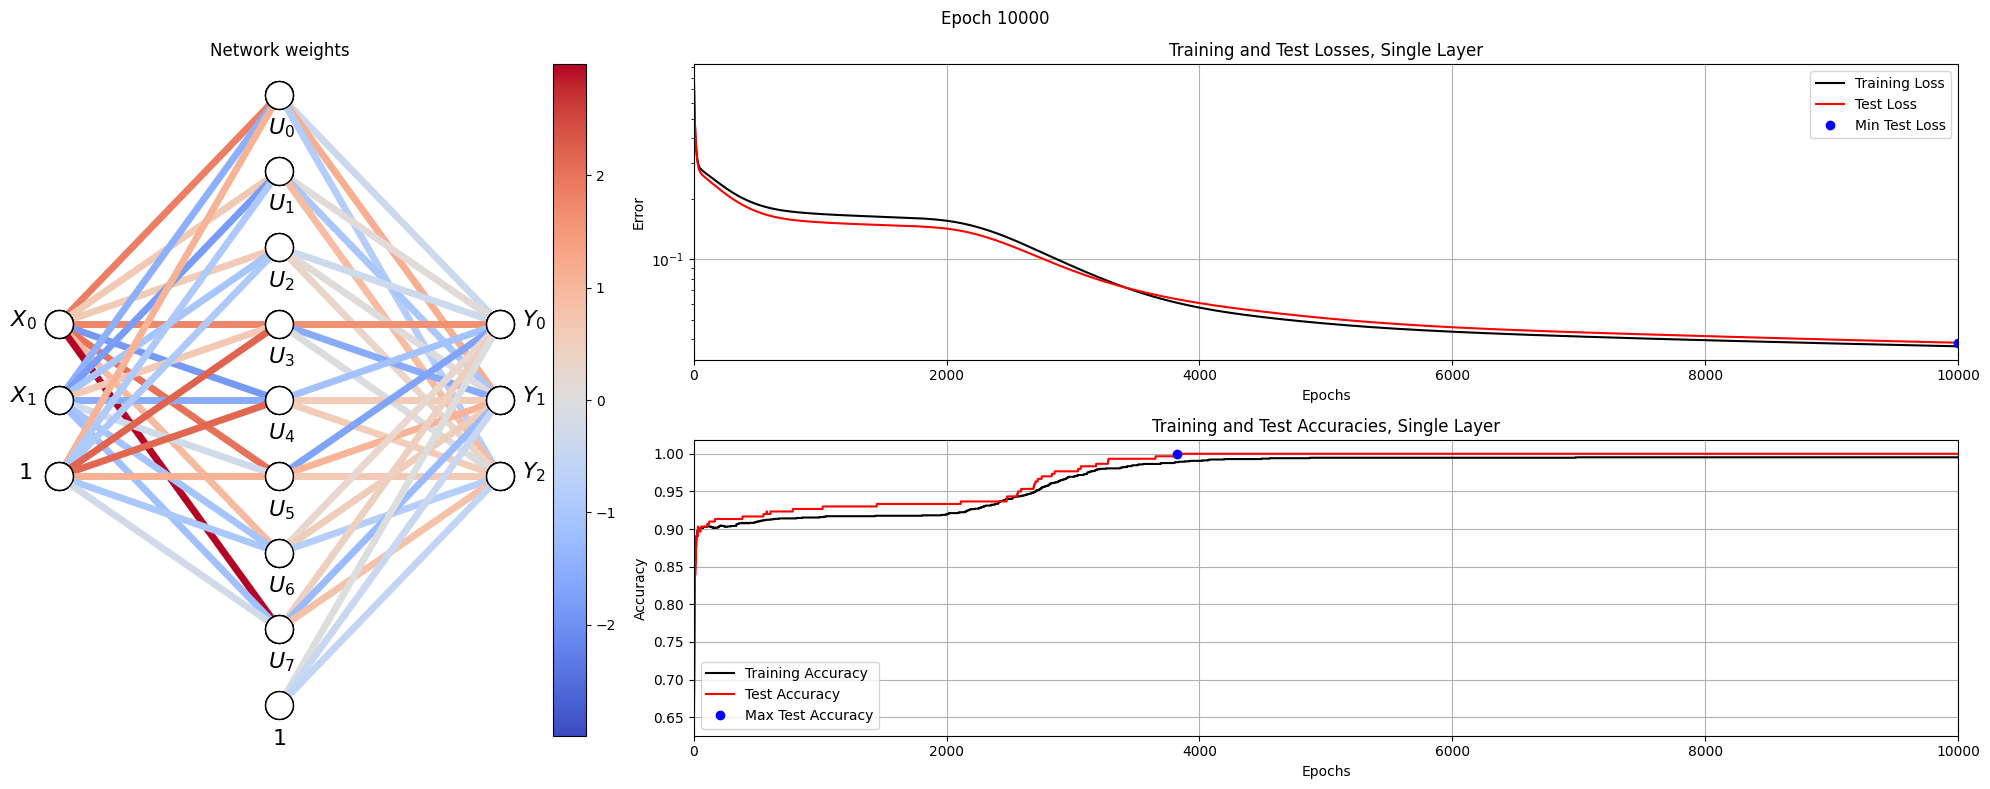

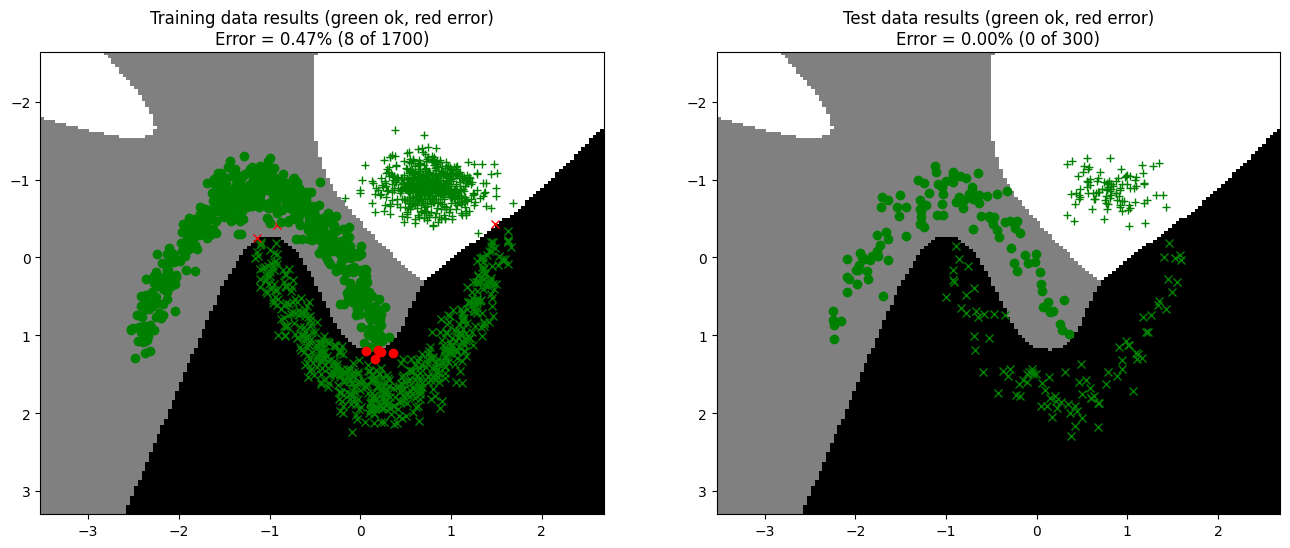

In [14]:
# --------------------------------------------
# === Your code here ========================= 
# --------------------------------------------
X, D, _ = loadDataset(3)

nInputs  = X.shape[1]
nClasses = D.shape[1]
nHidden  = 8

# Xavier-style initialization: scale each layer by 1 / sqrt(fan-in) so that the
# hidden units start in the non-saturated part of tanh. The weights must be
# random here (unlike the single-layer case) — identical hidden units would
# receive identical gradients forever and never differentiate.
rng = np.random.default_rng(seed=0)
W1_0 = rng.normal(loc=0.0, scale=1 / np.sqrt(nInputs), size=(nInputs, nHidden))
B1_0 = np.zeros((1, nHidden))
W2_0 = rng.normal(loc=0.0, scale=1 / np.sqrt(nHidden), size=(nHidden, nClasses))
B2_0 = np.zeros((1, nClasses))

params = {"epochs": 10000, "learningRate": 0.1, "normalize": True, "useTanhOutput": False}
# ============================================

trainMultiLayerOnDataset(3, 0.15, W1_0, B1_0, W2_0, B2_0, params)

#### **<span style="color:red">Question:</span>**

4. Optimize the training until you reach at least 99% test accuracy. Briefly motivate your choice of hyperparameters.

#### **<span style="color:green">Answer:</span>**

I used nHidden=8, epochs=10000, learningRate=0.1, normalize=True, no tanh output.
This gave 99.53% train and 100.00% test accuracy - every test point correct, and only
8 wrong out of 1700 training points.

This dataset has 3 classes and the single layer network only managed 90.0%, so the
boundaries are clearly not straight lines. 8 hidden units give enough bends to separate
all three regions. As with dataset 2, dropping the learning rate from 1.0 to 0.1 was what
made the difference, taking the result from 98.67% to 100%.

The accuracy curve shows why the long run is needed here: accuracy sits around 90% for the
first 2000 epochs, then climbs in steps until roughly epoch 6000 before flattening. The
network learns one class boundary at a time, so stopping early would have left the last
one unlearned.

Test accuracy being higher than train accuracy is not overfitting - it just means the few ambiguous points happened to land in the training split. With only 300 test points, 100% should not be read as a perfect classifier.

#### **2.4 Optimizing dataset 4**

Train accuracy: 0.9954
Test accuracy: 0.9858
Test data confusion matrix:
[[77  0  0  0  0  0  0  0  0  0]
 [ 0 86  0  0  0  0  0  0  0  0]
 [ 0  0 85  0  0  0  0  0  0  0]
 [ 0  0  0 98  0  0  0  0  0  1]
 [ 1  0  0  0 93  0  0  0  0  0]
 [ 0  0  0  0  0 78  0  0  2  0]
 [ 0  0  0  0  2  0 67  0  0  0]
 [ 0  0  0  0  0  0  0 86  0  0]
 [ 0  2  0  0  0  0  1  0 81  1]
 [ 0  0  0  0  0  1  0  1  0 80]]


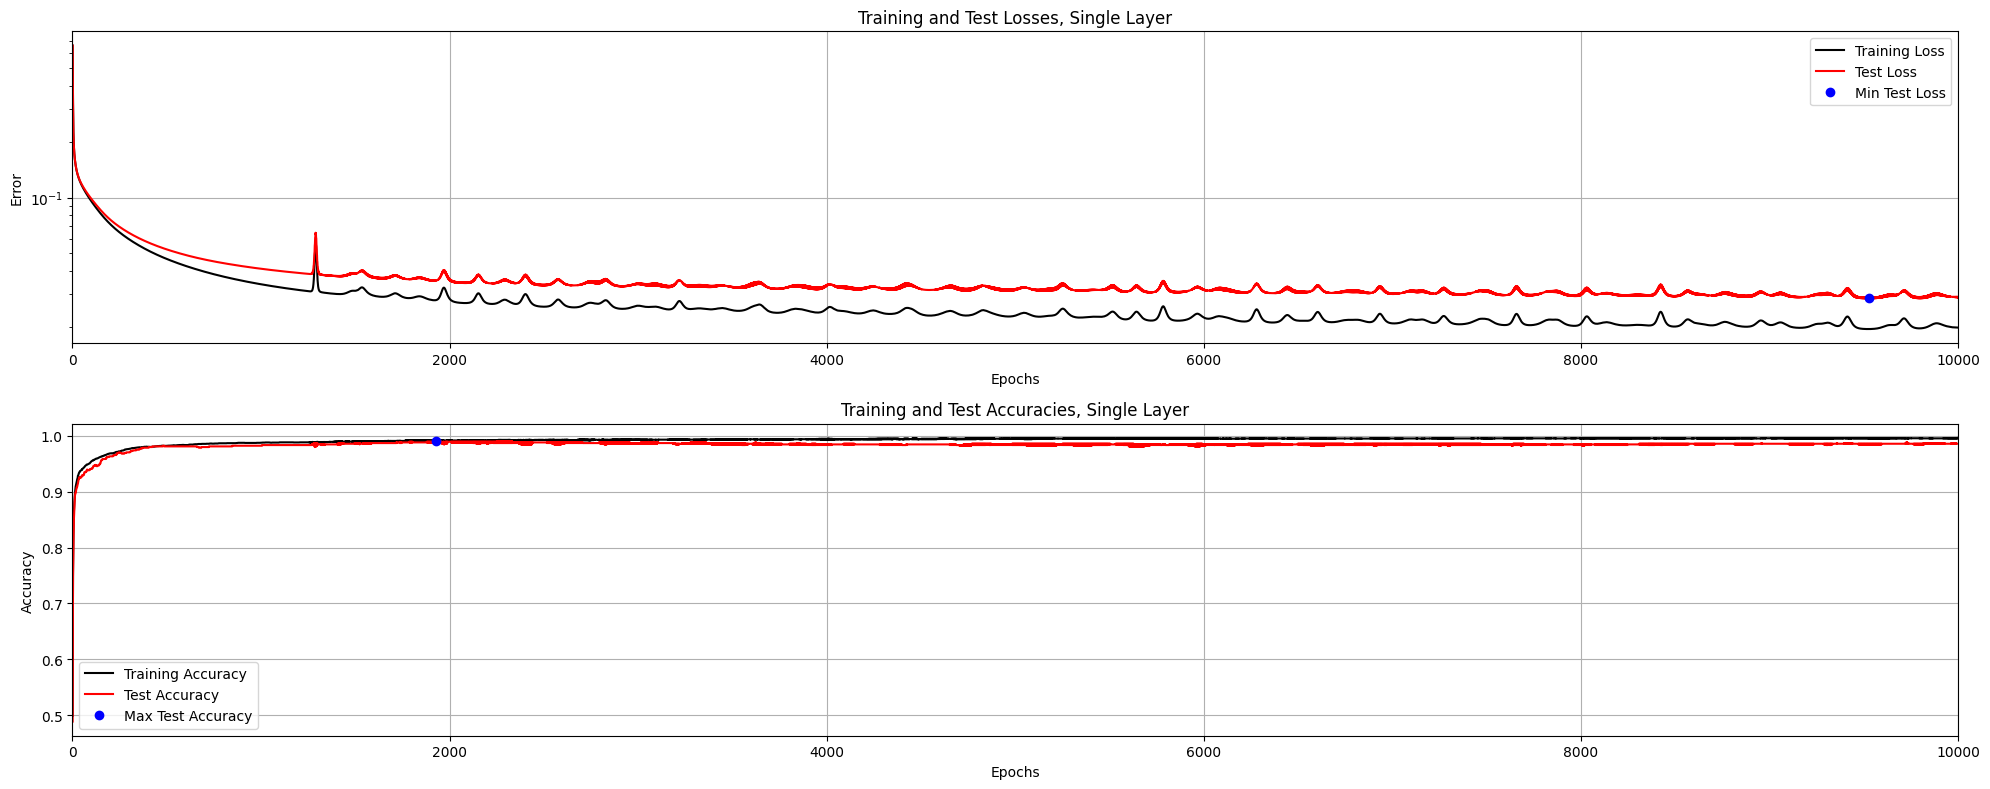

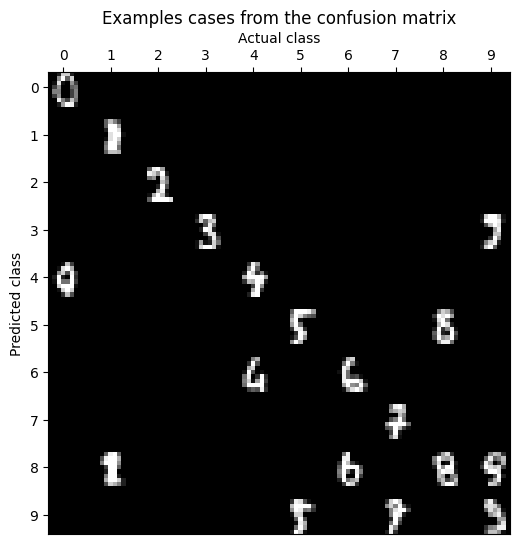

In [11]:
# --------------------------------------------
# === Your code here ========================= 
# --------------------------------------------
X, D, _ = loadDataset(4)

nInputs  = X.shape[1]
nClasses = D.shape[1]
nHidden  = 50

# Xavier-style initialization: scale each layer by 1 / sqrt(fan-in) so that the
# hidden units start in the non-saturated part of tanh. The weights must be
# random here (unlike the single-layer case) — identical hidden units would
# receive identical gradients forever and never differentiate.
rng = np.random.default_rng(seed=0)
W1_0 = rng.normal(loc=0.0, scale=1 / np.sqrt(nInputs), size=(nInputs, nHidden))
B1_0 = np.zeros((1, nHidden))
W2_0 = rng.normal(loc=0.0, scale=1 / np.sqrt(nHidden), size=(nHidden, nClasses))
B2_0 = np.zeros((1, nClasses))

params = {"epochs": 10000, "learningRate": 1.0, "normalize": True, "useTanhOutput": False}
# ============================================

trainMultiLayerOnDataset(4, 0.15, W1_0, B1_0, W2_0, B2_0, params)

#### **<span style="color:red">Question:</span>**

5. Optimize the training until you reach at least 96% test accuracy. Briefly motivate your choice of hyperparameters.

#### **<span style="color:green">Answer:</span>**

I used nHidden=50, epochs=10000, learningRate=1.0, normalize=True, no tanh output.
This gave 99.54% train and 98.58% test accuracy, well above the 96% target and much better
than the 93.36% the single layer network reached on the same data.

With 64 inputs and 10 classes this problem needs far more capacity than the 2D datasets.
50 hidden units sits between the input and output size and lets the network build simple
stroke-like features that several digits can share, without adding too many parameters.
Scaling the starting weights by 1/sqrt(64) matters here, because with 64 inputs plain
random weights would immediately push the hidden units into the flat part of tanh.
Normalizing is needed for the same reason, since pixel values are all positive and far
from zero mean.

Unlike the other three datasets, a learning rate of 1.0 works fine here and reaching the
target needed no tuning. The gradient is divided by N * nClasses in the backward pass, and
with 10 classes that makes the real step ten times smaller than it looks.